# Phase 3: Drought and wind

Two weather effects, both acting through the spread probability from Phase 2:

* **Dryness d** (0 = normal year, 1 = bone dry) stands for El Niño drought. It shrinks the chance that fuel *fails* to catch: **q = 1 − (1 − q_normal)(1 − d)**.
* **Wind** (speed V in m/s, plus a direction) boosts spread downwind and cuts it upwind. Each neighbour gets **p × e^(0.131·V·cos angle)**, using the angular coefficient fitted to a real wildfire by Alexandridis et al. (2008).

For the wind experiments, cells **smoulder for 10 steps** and keep trying to ignite their neighbours. With one-step burning a surviving fire always advances at the grid's speed limit, so wind could change where fire goes but not how fast.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the code is cloned from GitHub if that repo exists; otherwise copy the project folder
# to Google Drive as MyDrive/forest_fire.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/forest_fire"):
    repo = "https://github.com/nhamhhung/forest-fire-spread.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/forest_fire"]).returncode == 0:
        os.chdir("/content/forest_fire")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/forest_fire")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from forest_fire import experiments as ex
from forest_fire.grid import make_forest, ignite_point
from forest_fire.spread import run_fire
from forest_fire.plotting import plot_arrival
s = ex.Phase3Settings()

## 1. Drought: fraction burned vs dryness
Same forests at every dryness level, so changes come from the drought alone. 50 forests per point here; the script uses 100.

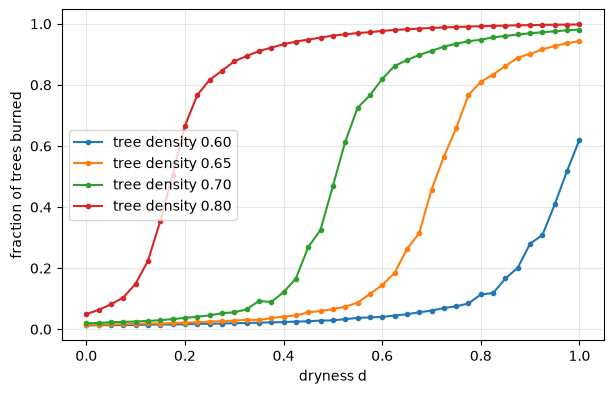

,density,d50,d50_err
0,0.60,0.956,0.001
1,0.65,0.700,0.001
2,0.70,0.497,0.001
3,0.80,0.160,0.000


In [2]:
dry = pd.concat([ex.dryness_sweep(200, p, s.dryness, s.q_normal, 50, s.seed) for p in s.densities], ignore_index=True)
fig, ax = plt.subplots(figsize=(7, 4.3))
for p, d in dry.groupby("density"):
    ax.plot(d["dryness"], d["fraction_burned"], "o-", ms=3, label=f"tree density {p:.2f}")
ax.set(xlabel="dryness d", ylabel="fraction of trees burned"); ax.legend(); ax.grid(alpha=.3); plt.show()
pd.DataFrame([{"density": p, **ex.critical_dryness(d)} for p, d in dry.groupby("density")]).round(3)

* For every density there is a **critical dryness** where fires switch from small to forest-wide, the same percolation switch as Phases 1–2, now driven by weather.
* **The denser the forest, the less drought it takes.** A 65%-cover forest that barely burns in a normal year (about 1.5%) burns **80%** at dryness 0.8.
* El Niño reading: if a typical year sits just below the critical dryness, a drought year that pushes past it gives a fire season that is *qualitatively* different, not just a bit worse.

## 2. Wind: shape after 120 steps
One spark in the centre of the same forest; only the wind changes.

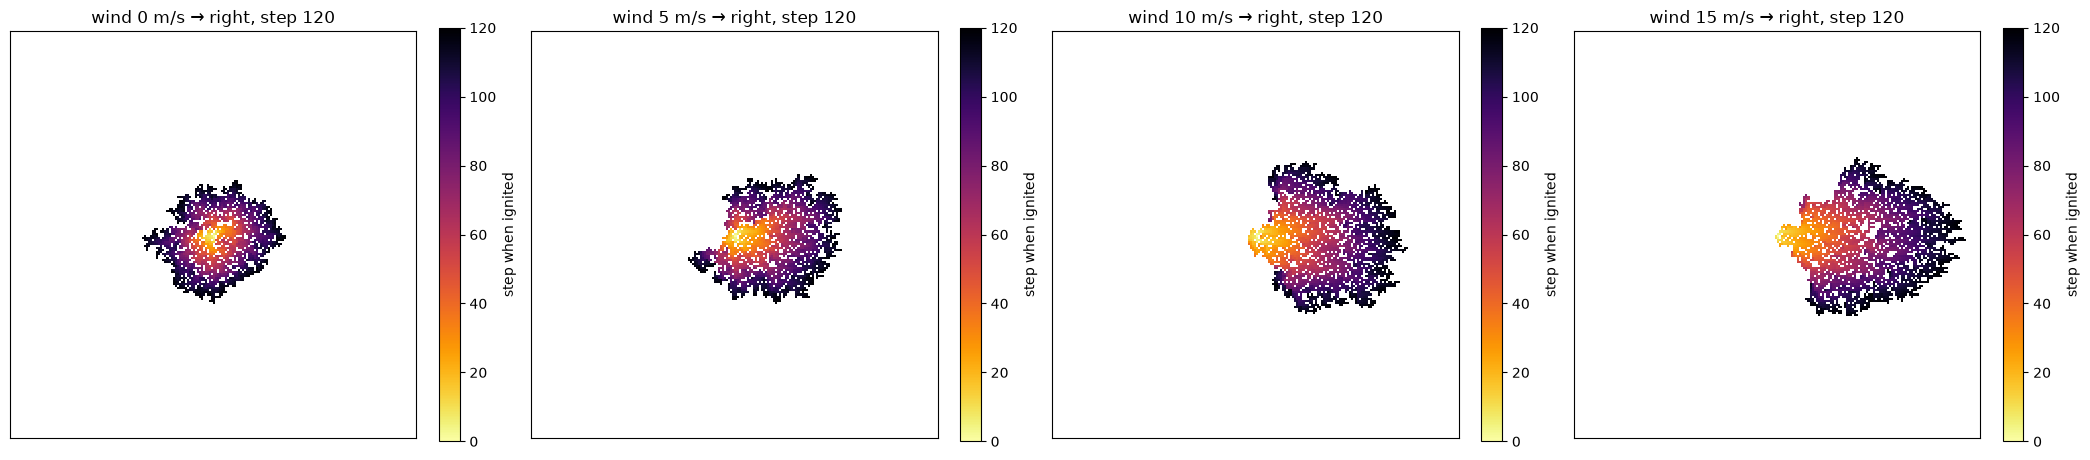

In [3]:
forest = make_forest(200, s.wind_density, np.random.default_rng(21))
fig, axes = plt.subplots(1, 4, figsize=(21, 5))
for ax, v in zip(axes, [0, 5, 10, 15]):
    _, arrival, _ = run_fire(ignite_point(forest), s.wind_q, s.wind_neighbourhood, 5, 0.0, v, s.burn_steps)
    plot_arrival(np.where(arrival <= 120, arrival, -1), ax=ax, title=f"wind {v} m/s → right, step 120")
plt.tight_layout(); plt.show()

## 3. Wind: speed and shape, averaged over 30 forests

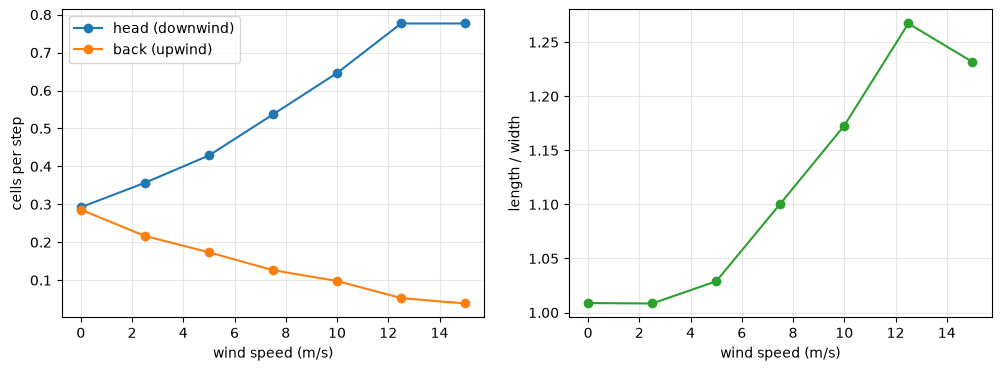

,wind_speed,head_speed,back_speed,length_to_width
0,0.0,0.292,0.286,1.009
1,2.5,0.357,0.217,1.008
2,5.0,0.429,0.173,1.029
3,7.5,0.537,0.126,1.100
4,10.0,0.646,0.098,1.173
5,12.5,0.777,0.053,1.267
6,15.0,0.777,0.038,1.232


In [4]:
w = ex.summarise_wind(ex.wind_sweep(ex.Phase3Settings(wind_runs=30)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(w["wind_speed"], w["head_speed"], "o-", label="head (downwind)")
axes[0].plot(w["wind_speed"], w["back_speed"], "o-", label="back (upwind)")
axes[0].set(xlabel="wind speed (m/s)", ylabel="cells per step"); axes[0].legend()
axes[1].plot(w["wind_speed"], w["length_to_width"], "o-", color="C2"); axes[1].set(xlabel="wind speed (m/s)", ylabel="length / width")
for ax in axes: ax.grid(alpha=.3)
plt.show()
w[["wind_speed", "head_speed", "back_speed", "length_to_width"]].round(3)

## Takeaways
* **Wind makes the head run.** At 10 m/s the head spreads more than twice as fast as with no wind, while the back of the fire nearly stalls (about 3× slower). The burnt area becomes egg-shaped with the spark at its back edge, as in real wind-driven fires.
* **Limits of the grid:** above about 12 m/s the downwind ignition chance hits 1 and the head cannot go faster than one cell per step. The stretching (length/width ≈ 1.2–1.3) is much milder than in real wind-driven fires, because nothing here throws embers ahead of the front and the flanks still spread at their no-wind speed.
* **Drought and wind together** are the El Niño fire-season recipe: drought decides *whether* a fire can carry across the landscape, wind decides *how fast and in which direction* it goes.